# Basic Convexity Usage

In this notebook, we will demonstrate some usage of the Convexity SDK, allowing us to do a wide variety of quantitative research with tools at our fingertips. We will demonstrate the basic use cases such as building a simple benchmarking tool (comparing strategies and buy-and-hold), then we will demonstrate how data analysis can be effectively streamlined using Convexity, develop a few simple strategies ranging from basic TA strats to predictive modeling strats using PyTorch. We will then build a portfolio optimization strategy and backtest it.

The first step is to import Convexity and some of the useful Python libraries. Below is a buy-and-hold strategy. When the strategy instance is created, the strategy computes how many shares of SPY it can purchase and then executes a market order. It doesn't need any event subscriptions.

In [3]:
import convexity as cx
import pandas as pd
import numpy as np
import math
from decimal import Decimal
from datetime import timedelta, time

import pandas as pd
import matplotlib.pyplot as plt

In [6]:
class BuyAndHold(cx.Strategy):
    metadata = cx.StrategyMetadata("buy-hold", version="1")
    contract = cx.StrategyContract(instruments=("SPY",))

    def on_start(self, context):
        account = context.account

        # if account is None or account.base_currency != "USD":
        #    raise ValueError("This strategy expects a USD reporting account.")
        # if not account.cash_balances_complete or account.available_funds is None:
        #    raise ValueError("Cash balances and available funds are required.")

        price = context.price("SPY", max_age=timedelta(days=4))

        # These are explicit strategy decisions.
        fee_reserve = Decimal("10")
        price_buffer = Decimal("0.01")

        usd_cash = account.cash_balances.get("USD", Decimal(0))
        budget = max(
            Decimal(0),
            min(usd_cash, account.available_funds)
            - account.reserved
            - fee_reserve,
        )
        shares = int(budget // (price * (1 + price_buffer)))

        if shares == 0:
            return None

        return cx.SubmitOrder.market(
            "SPY", "BUY", shares,
            time_in_force="DAY",
            client_order_id="entry",
        )


result = await cx.Research("2025-01-02", "2026-10-12").run_async(
    BuyAndHold,
    initial_cash=100_000,
    base_currency="USD",
)
print(result.metrics, result.positions, result.open_orders)

{'final_cash': Decimal('961.32'), 'final_equity': Decimal('131682.12'), 'total_return': Decimal('0.3168212'), 'max_drawdown': Decimal('0.1882317896163664556472423344'), 'fees': Decimal('1'), 'borrow_cost': Decimal('0')} {'buy-hold': {'SPY': Position(quantity=168, average_cost=Decimal('589.51'), realized_pnl=Decimal('0'), currency='USD')}} ()


The backtest gives us some useful information. We can trace the value of the portfolio throughout time, trace the borrow cost if on margin, fees paid (simulated), track realized and unrealized profits, drawdowns, account composition at the end of the period, and all of this data can easily be converted to pandas dataframes which we can use to do some more analysis on the results.

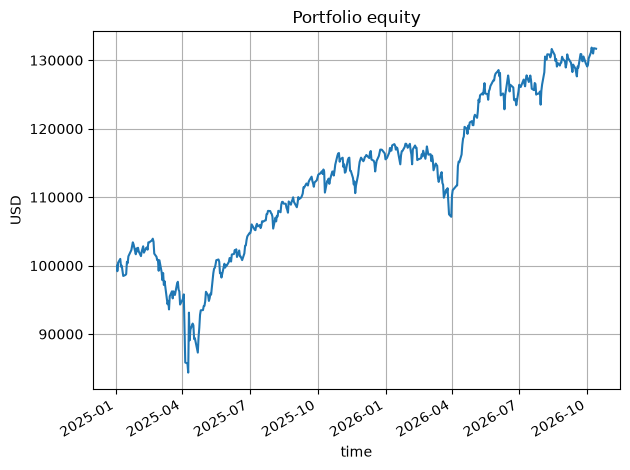

In [ ]:
equity = pd.DataFrame(result.equity).set_index("time")
equity.index = pd.to_datetime(equity.index, utc=True)
equity[["cash", "equity"]] = equity[["cash", "equity"]].astype(float)

equity["equity"].plot(
    title="Portfolio equity", ylabel="USD", grid=True,
)
plt.tight_layout()
plt.show()

Now let's try building a different strategy. Let's test the hypothesis that it's better to hold overnight and stay flat during the day (with respect to US market hours: 9:30AM to 4:00PM). We will build a strategy that acts on clock events, sell flat at the open, buy as much as you can overnight.
- A few things I would suspect before running the backtest. Turnover would be insane if we are trading the entire portfolio twice a day. Transaction costs will likely eat up a huge amount of the profits in a realistic setting and furthermore in real life, for large portfolios this amount of turnover would simply be impossible to go undetected in the markets and would affect prices. Nonetheless, let's test out this hypothesis.
- The difference between just taking historical data and measuring raw cumulative returns overnight vs intraday is that we are now running inside a simulated trading environment.

In [4]:
class OvernightHold(cx.Strategy):
    metadata = cx.StrategyMetadata("overnight_hold", version="2")
    contract = cx.StrategyContract(
        instruments=("SPY",),
        subscriptions=(
            cx.EventSubscription(cx.Timer, schedule=cx.ClockSchedule("enter", at=time(15, 50))),
            cx.EventSubscription(cx.Timer, schedule=cx.ClockSchedule("exit", at=time(9, 30))),
            cx.EventSubscription(cx.Rejection),
        ),
    )

    def on_timer(self, event, context):
        # Stable for retries of this decision, unique for the next session.
        order_id = f"{event.name}:{event.time.isoformat()}"
        if event.name == "enter" and not context.position("SPY") and not context.pending("SPY"):
            price = context.price("SPY", max_age=timedelta(days=4))
            account = context.account
            if account is None or account.available_funds is None or not account.cash_balances_complete:
                raise ValueError("Complete cash balances and available funds are required.")
            budget = max(
                Decimal(0),
                min(account.cash_balances.get("USD", Decimal(0)), account.available_funds)
                - account.reserved - Decimal("10"),
            )
            shares = int(budget // (price * Decimal("1.01")))
            if shares:
                return cx.SubmitOrder.market("SPY", "BUY", shares,
                                             time_in_force="DAY", client_order_id=order_id)
        if event.name == "exit" and context.position("SPY") > 0 and not context.pending("SPY"):
            return cx.SubmitOrder.market("SPY", "SELL", context.position("SPY"),
                                         time_in_force="DAY", client_order_id=order_id)

    def on_rejection(self, event, context):
        # This example stops visibly instead of hiding a rejected daily entry.
        raise RuntimeError(f"Order rejected at {event.time}: {event.reason}")

result = await cx.Research("2025-01-02", "2026-10-12").run_async(
    OvernightHold,
    initial_cash=100_000,
    base_currency="USD",
)
print(result.metrics, result.positions, result.open_orders)

{'final_cash': Decimal('1668.13'), 'final_equity': Decimal('98926.88'), 'total_return': Decimal('-0.0107312'), 'max_drawdown': Decimal('0.1878445245817509909134305967'), 'fees': Decimal('883'), 'borrow_cost': Decimal('0')} {'overnight_hold': {'SPY': Position(quantity=125, average_cost=Decimal('778.10'), realized_pnl=Decimal('-186.37'), currency='USD')}} ()


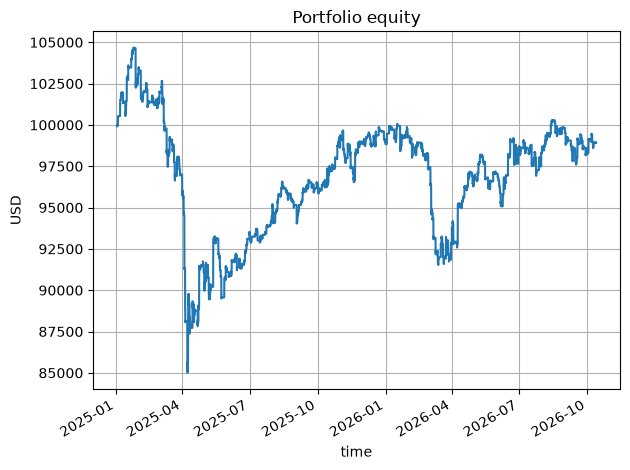

In [5]:
equity = pd.DataFrame(result.equity).set_index("time")
equity.index = pd.to_datetime(equity.index, utc=True)
equity[["cash", "equity"]] = equity[["cash", "equity"]].astype(float)

equity["equity"].plot(
    title="Portfolio equity", ylabel="USD", grid=True,
)
plt.tight_layout()
plt.show()

So we notice that it dramatically underperforms buy-and-hold. We also notice that on huge gap down days, this strategy gets killed and since it has virtually no exposure to the typical US market hour trading, which can provide some gap closure and reversal of overnight trading, this strategy just closes the trades at a loss frequently. Nonetheless, this is an example of how to build a strategy that trades clock events. Just for fun, let's test out if we never held overnight and just bought at the open and sold at the close.

In [9]:
class IntradayHold(cx.Strategy):
    metadata = cx.StrategyMetadata("intraday_hold", version="1")
    contract = cx.StrategyContract(
        instruments = ("SPY",),
        subscriptions = (
            cx.EventSubscription(cx.Timer, schedule=cx.ClockSchedule("enter", at=time(9, 30))),
            cx.EventSubscription(cx.Timer, schedule=cx.ClockSchedule("exit", at=time(15, 50))),
        )
    )

    def on_timer(self, event, context):
        # Stable for retries of this decision, unique for the next session.
        order_id = f"{event.name}:{event.time.isoformat()}"
        if event.name == "enter" and not context.position("SPY") and not context.pending("SPY"):
            price = context.price("SPY", max_age=timedelta(days=4))
            account = context.account
            if account is None or account.available_funds is None or not account.cash_balances_complete:
                raise ValueError("Complete cash balances and available funds are required.")
            budget = max(
                Decimal(0),
                min(account.cash_balances.get("USD", Decimal(0)), account.available_funds)
                - account.reserved - Decimal("10"),
            )
            shares = int(budget // (price * Decimal("1.01")))
            if shares:
                return cx.SubmitOrder.market("SPY", "BUY", shares, time_in_force="DAY", client_order_id=order_id)
        if event.name == "exit" and context.position("SPY") > 0 and not context.pending("SPY"):
            return cx.SubmitOrder.market("SPY", "SELL", context.position("SPY"), time_in_force="DAY", client_order_id=order_id)

result = await cx.Research("2025-01-02", "2026-10-12").run_async(
    IntradayHold,
    initial_cash=100_000,
    base_currency="USD",
)
print(result.metrics, result.positions, result.open_orders)

{'final_cash': Decimal('99763.48'), 'final_equity': Decimal('99763.48'), 'total_return': Decimal('-0.0023652'), 'max_drawdown': Decimal('0.1092353449748409153315777112'), 'fees': Decimal('860'), 'borrow_cost': Decimal('0')} {'intraday_hold': {'SPY': Position(quantity=0, average_cost=Decimal('0'), realized_pnl=Decimal('623.48'), currency='USD')}} ()


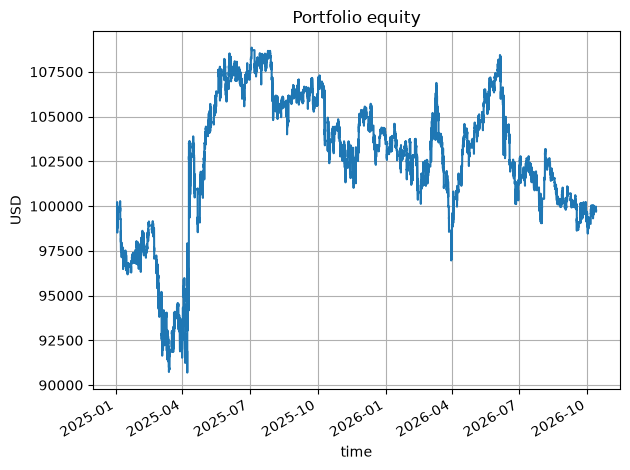

In [10]:
equity = pd.DataFrame(result.equity).set_index("time")
equity.index = pd.to_datetime(equity.index, utc=True)
equity[["cash", "equity"]] = equity[["cash", "equity"]].astype(float)

equity["equity"].plot(
    title="Portfolio equity", ylabel="USD", grid=True,
)
plt.tight_layout()
plt.show()

So holding during the day has an almost entirely different equity curve than holding overnight. That's interesting. Maybe we should do some data analysis and see if we can explain some of this. The strategy seemed to climb out of the "hole" much quicker than the overnight strategy as it holds through intraday bullish rallies and avoids overnight pullbacks. However, it spends much of the rest of the trading period slowly bleeding money. Now that we've taken a look on how to build some basic strategies. Let's look at how to build a slightly more sophisticated system that makes use of portfolio diversification. We will build a few different portfolios and measure their performance.